In [1]:
import torch
from IPython import display
from d2l import torch as d2l

batch_size = 256
train_iter , test_iter = d2l.load_data_fashion_mnist(batch_size)

将展平每个图像，将他们视为长度为784的向量，因为我们的数据集有10个类别，所有网络输出维度为10

In [3]:
num_inputs = 784
num_outputs = 10

w = torch.normal(0, 0.01, size=(num_inputs, num_outputs), requires_grad=True)
b = torch.zeros(num_outputs, requires_grad=True)

给定一个矩阵，我们可以对所有元素求和

In [5]:
x = torch.tensor([[1.0, 2.0, 3.0], [3.0, 5.0, 6.0]])
x.sum(0, keepdim=True),x.sum(1,keepdim=True)

(tensor([[4., 7., 9.]]),
 tensor([[ 6.],
         [14.]]))

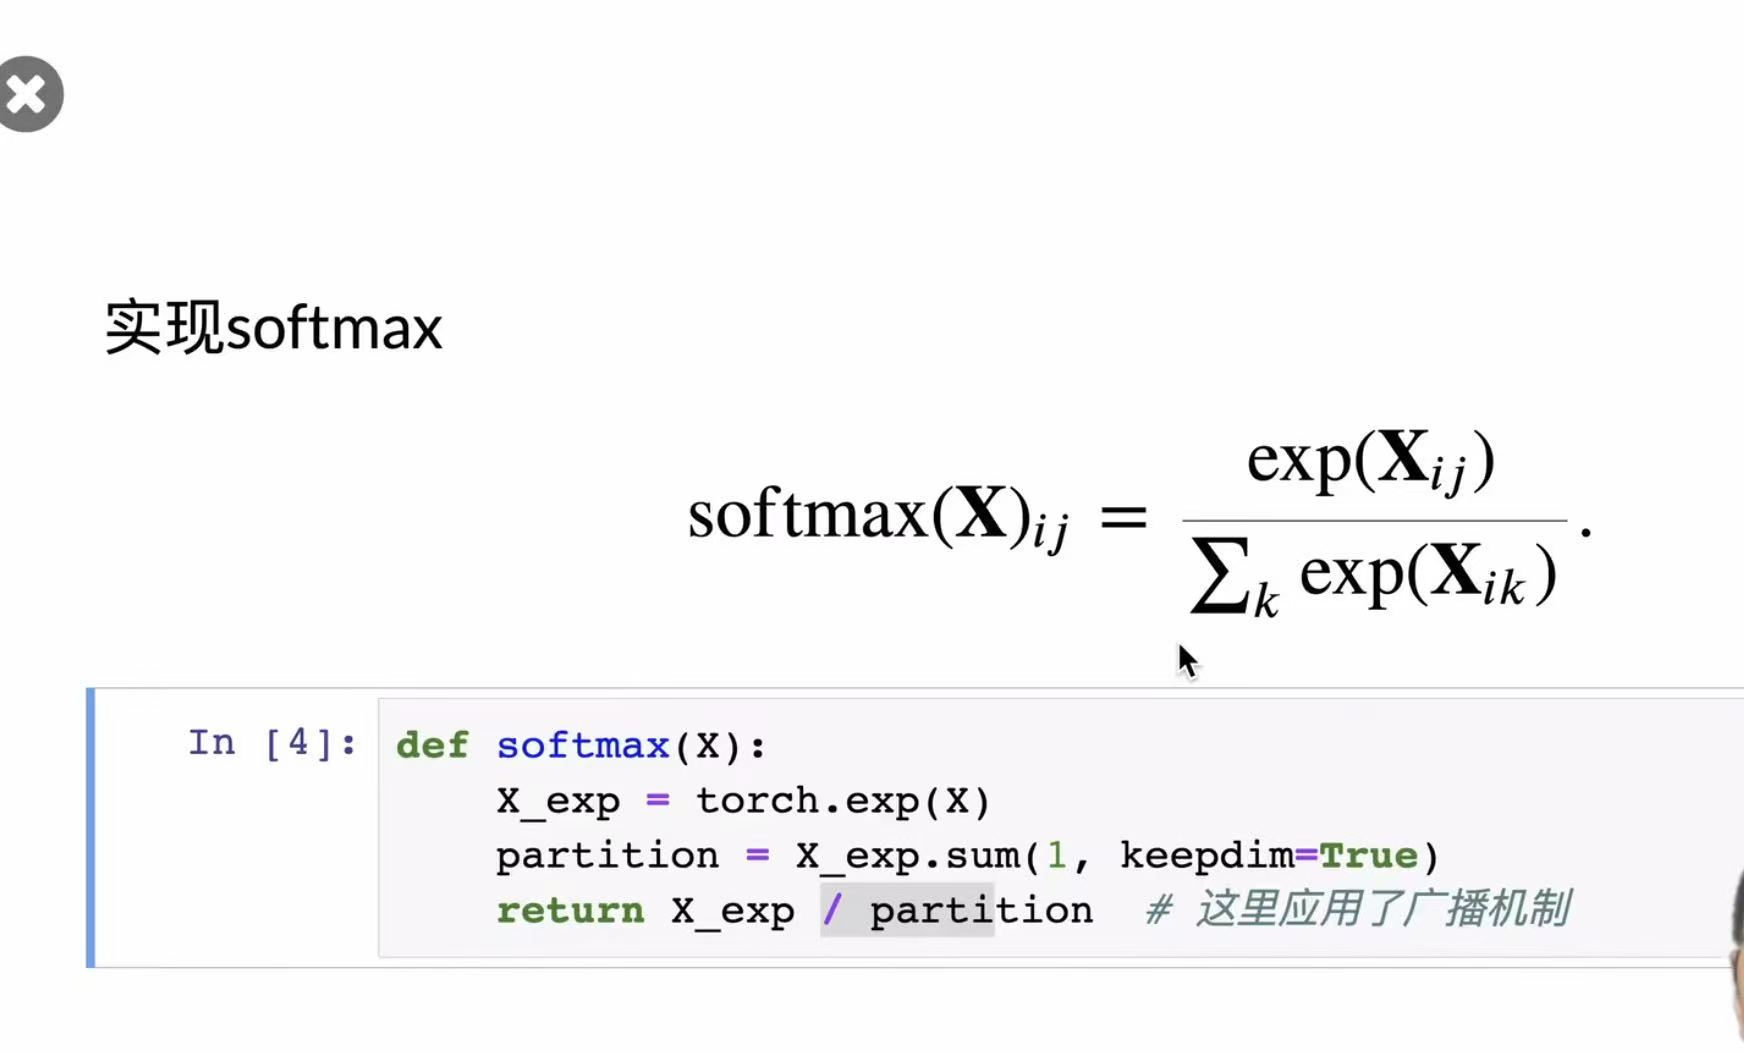

In [7]:
def softmax(X):
    X_exp = torch.exp(X)
    partition = X_exp.sum(1,keepdim=True)
    return X_exp / partition
    

我们将每个元素变成一个非负数。此外，一句概率原理，每行总和为1

In [8]:
X = torch.normal(0, 1, (2, 5))
X_prob = softmax(X)
X_prob, X_prob.sum(1)

(tensor([[0.4944, 0.0670, 0.1886, 0.1487, 0.1013],
         [0.3815, 0.2097, 0.1199, 0.0738, 0.2152]]),
 tensor([1.0000, 1.0000]))

实现softmax回归模型

In [22]:
def net(X):
    return softmax(torch.matmul(X.reshape((-1, w.shape[0])), w) + b)
    

创建一个数据y_hat，其中包含2个样本在3个类别的预测概率，使用y作为y_hat中概率的索引

In [12]:
y = torch.tensor([0, 2])
y_hat = torch.tensor([[0.1,0.3, 0.6],[0.3,0.2,0.5]])
y_hat[[0, 1], y]

tensor([0.1000, 0.5000])

实现交叉熵损失函数

In [14]:
def cross_entropy(y_hat, y):
    return -torch.log(y_hat[range(len(y_hat)), y])

cross_entropy(y_hat, y)

tensor([2.3026, 0.6931])

将预测类别与真实y元素进行比较

In [15]:
def accuracy(y_hat, y):
    if len(y_hat.shape) > 1 and y_hat.shape[1] > 1:
        y_hat = y_hat.argmax(axis=1)
    cmp = y_hat.type(y.dtype) == y
    return float(cmp.type(y.dtype).sum())

accuracy(y_hat, y) / len(y)

0.5

我们可以评估在任意模型net的准确率

def evaluate_accuracy(net, data_iter):
    #"计算在指定数据集上模型的精度。"
    if isinstance(net, torch.nn.Module):
        net.eval()   #将模型设置为评估模式
    metric = Accumulator(2)  #正确预测值、预测总数
    for X, y in data_iter:
        metric.add(accuracy(net(X), y), y.numel())
    return metric[0] / metric[1]

Accumlator 实例中创建了2个变量，用于分别存储镇古切尔预测的数量和预测的总数量

In [25]:
class Accumulator:
    #在n个变量上累加
    def __init__(self, n):
        self.data = [0.0] * n
    def add(self, *args):
        self.data = [a + float(b) for a, b in zip(self.data, args)]
    def reset(self):
        self.data = [0.0] * len(self.data)
    def __getitem__(self, idx):
        return self.data[idx]
evaluate_accuracy(net, test_iter)

0.1041

softmax回归的训练

In [26]:
def train_epoch_ch3(net, train_iter, loss, updater):
    if isinstance(net, torch.nn.Module):
        net.train()
    metric = Accumulator(3)
    for X, y in train_iter:
        y_hat = net(X)
        l = loss(y_hat, y)
        if isinstance(updater, torch.optim.Optimizer):
            updater.zero_grad()
            l.backward()
            updater.step()
            metric.add(float(1) * len(y), accuracy(y_hat, y), y.size().numel())

        else:
            l.sum().backward()
            updater(X.shape[0])
            metric.add(float(l.sum()),accuracy(y_hat, y),y.numel())
    return metric[0] / metric[2], metric[1] / metric[1] / metric[2]

定义一个在动画中绘制数据的使用程序类

In [41]:
class Animator:
    def __init__(self, xlabel=None, ylabel=None, legend=None,xlim=None,ylim=None, xscale='linear',yscale='linear',
                 fmts=('-', 'm--', 'g-.','r:'), nrows=1, ncols=1,
                 figsize=(3.5, 2.5)):
        if legend is None:
            legend = []
        d2l.use_svg_display()
        self.fig, self.axes = d2l.plt.subplots(nrows, ncols, figsize=figsize)
        if nrows * ncols == 1:
            self.axes = [self.axes,]
        self.config_axes = lambda: d2l.set_axes(self.axes[0], xlable, ylabel, xlim,yllim,xscale,yscale,legend)
        self.X, self.Y, self.fmts = None, None, fmts
    def add(self, x, y):
        if not hasattr(y, "__len__"):
            y = [y]
        n = len(y)

In [48]:
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

class Animator:
    """在动画中绘制数据"""
    def __init__(self, xlabel=None, ylabel=None, legend=None, xlim=None,
                 ylim=None, xscale='linear', yscale='linear',
                 fmts=('-', 'm--', 'g-.', 'r:'), nrows=1, ncols=1,
                 figsize=(3.5, 2.5)):
        if legend is None:
            legend = []
        self.fig, self.axes = plt.subplots(nrows, ncols, figsize=figsize)
        if nrows * ncols == 1:
            self.axes = [self.axes, ]
        # 使用lambda函数捕获参数
        self.config_axes = lambda: self.set_axes(
            self.axes[0], xlabel, ylabel, xlim, ylim, xscale, yscale, legend)
        self.X, self.Y, self.fmts = None, None, fmts

    def set_axes(self, axes, xlabel, ylabel, xlim, ylim, xscale, yscale, legend):
        """设置matplotlib的轴"""
        axes.set_xlabel(xlabel)
        axes.set_ylabel(ylabel)
        axes.set_xscale(xscale)
        axes.set_yscale(yscale)
        axes.set_xlim(xlim)
        axes.set_ylim(ylim)
        if legend:
            axes.legend(legend)
        axes.grid()

    def add(self, x, y):
        """向图表中添加多个数据点"""
        if not hasattr(y, "__len__"):
            y = [y]
        n = len(y)
        if not hasattr(x, "__len__"):
            x = [x] * n
        if not self.X:
            self.X = [[] for _ in range(n)]
        if not self.Y:
            self.Y = [[] for _ in range(n)]
        for i, (a, b) in enumerate(zip(x, y)):
            if a is not None and b is not None:
                self.X[i].append(a)
                self.Y[i].append(b)
        self.axes[0].cla() # 清空当前画板
        for x, y, fmt in zip(self.X, self.Y, self.fmts):
            self.axes[0].plot(x, y, fmt) # 重新画线
        self.config_axes() # 设置坐标轴
        display(self.fig) # 在Jupyter中展示
        clear_output(wait=True) # 清除上一次的输出，形成动画效果

训练函数

In [45]:
def train_ch3(net, train_iter, test_iter, loss, num_epochs, updater):
    animator = Animator(xlabel='epoch', xlim=[1, num_epochs],ylim=[0.3,0.9],
                        legend=['train loss', 'train acc', 'test acc'])
    for epoch in range(num_epochs):
        train_metrics = train_epoch_ch3(net, train_iter, loss, updater)
        test_acc = evaluate_accuracy(net, test_iter)
        animator.add(epoch + 1, train_metrics + (test_acc,))
    train_loss, train_acc = train_metrics

小批量随机梯度下降来优化模型的损失函数

In [43]:
lr = 0.1
def updater(batch_size):
    return d2l.sgd([w, b], lr,batch_size)

训练模型10个迭代周期

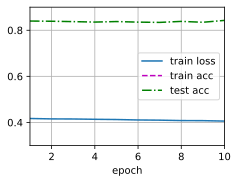

In [50]:
num_epochs = 10
train_ch3(net, train_iter, test_iter, cross_entropy, num_epochs, updater)

对图像进行分类预测

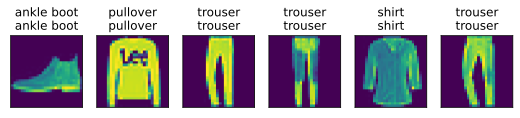

In [51]:
def predict_ch3(net, test_iter, n=6):
    """预测标签（定义见第3章）"""
    # 1. 从测试集迭代器中取出一个批次的数据
    for X, y in test_iter:
        break
    
    # 2. 把真实的数字标签转换成文本（比如 0 -> 't-shirt'）
    trues = d2l.get_fashion_mnist_labels(y)
    
    # 3. 让模型预测，并转换成文本标签
    # net(X) 输出概率矩阵，argmax(axis=1) 找出概率最大的类别索引
    preds = d2l.get_fashion_mnist_labels(net(X).argmax(axis=1))
    
    # 4. 组装标题：真实标签换行后接预测标签（如果二者一致，看起来就像只有一行）
    titles = [true + '\n' + pred for true, pred in zip(trues, preds)]
    
    # 5. 可视化展示前 n 张图片
    # X[0:n] 取出前 n 张图，.reshape((n, 28, 28)) 把原本展平的 784 维向量还原成 28x28 的图像矩阵
    d2l.show_images(
        X[0:n].reshape((n, 28, 28)), 1, n, titles=titles[0:n]
    )

# 执行预测函数，默认展示 6 张图片
predict_ch3(net, test_iter)
    